In [1]:

import pandas as pd
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

from google.colab import files

uploaded = files.upload()


Saving Sample - Superstore.csv to Sample - Superstore.csv


In [7]:

import os

print(os.listdir('/content'))


['.config', 'Sample - Superstore.csv', 'sample_data']


In [12]:
import pandas as pd

file_name = list(uploaded.keys())[0]

# Specifying the encoding to handle special characters commonly found in this dataset
df = pd.read_csv(file_name, encoding='windows-1252')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [13]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [14]:

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [15]:

print("Total duplicate rows:")
print(df.duplicated().sum())


Total duplicate rows:
0


In [16]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 9994
Number of columns: 21


In [17]:

df.describe()


,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [18]:

# Create a copy of original dataset

cleaned_df = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", cleaned_df.shape)

print("Dataset copy created successfully!")


Original dataset: (9994, 21)
Working dataset: (9994, 21)
Dataset copy created successfully!


In [19]:



cleaned_df.columns = (
    cleaned_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Updated column names:")
print(cleaned_df.columns.tolist())


Updated column names:
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub-category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


In [20]:



for col in cleaned_df.select_dtypes(include="object").columns:
    cleaned_df[col] = cleaned_df[col].str.strip()

print("Extra spaces removed successfully!")


Extra spaces removed successfully!


In [21]:

duplicates_before = cleaned_df.duplicated().sum()

print("Duplicate rows before cleaning:", duplicates_before)


Duplicate rows before cleaning: 0


In [22]:

cleaned_df = cleaned_df.drop_duplicates()

duplicates_after = cleaned_df.duplicated().sum()

print("Duplicate rows after cleaning:", duplicates_after)


Duplicate rows after cleaning: 0


In [23]:

print(cleaned_df.isnull().sum())


row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
country          0
city             0
state            0
postal_code      0
region           0
product_id       0
category         0
sub-category     0
product_name     0
sales            0
quantity         0
discount         0
profit           0
dtype: int64


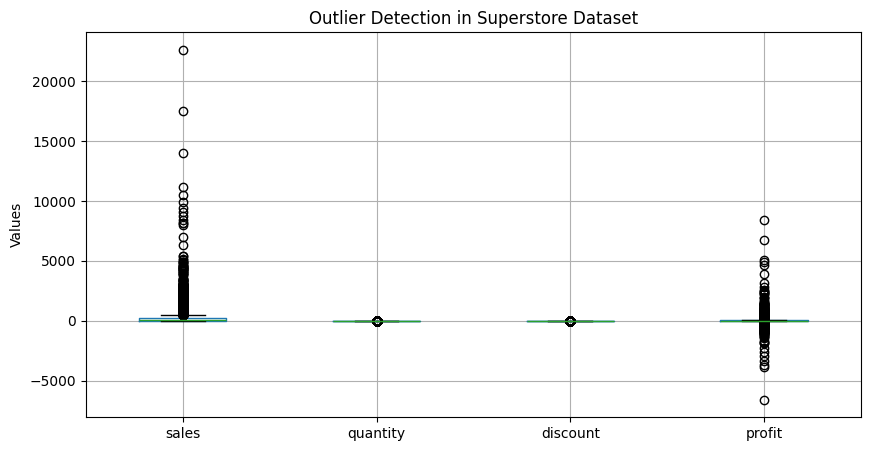

In [24]:

import matplotlib.pyplot as plt

cleaned_df[['sales', 'quantity', 'discount', 'profit']].boxplot(
    figsize=(10, 5)
)

plt.title("Outlier Detection in Superstore Dataset")
plt.ylabel("Values")
plt.show()


In [25]:



columns = ['sales', 'quantity', 'discount', 'profit']

for col in columns:

    Q1 = cleaned_df[col].quantile(0.25)
    Q3 = cleaned_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = cleaned_df[
        (cleaned_df[col] < lower_limit) |
        (cleaned_df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Outliers found:", len(outliers))



Column: sales
Lower limit: -271.71000000000004
Upper limit: 498.93
Outliers found: 1167

Column: quantity
Lower limit: -2.5
Upper limit: 9.5
Outliers found: 170

Column: discount
Lower limit: -0.30000000000000004
Upper limit: 0.5
Outliers found: 856

Column: profit
Lower limit: -39.724125
Upper limit: 70.816875
Outliers found: 1881


In [26]:

print("Duplicate rows:",
      cleaned_df.duplicated().sum())


Duplicate rows: 0


In [27]:

print("FINAL DATASET VALIDATION")

print("Total rows:", cleaned_df.shape[0])
print("Total columns:", cleaned_df.shape[1])

print("Missing values:",
      cleaned_df.isnull().sum().sum())

print("Duplicate rows:",
      cleaned_df.duplicated().sum())

print("\nData types:")
print(cleaned_df.dtypes)


FINAL DATASET VALIDATION
Total rows: 9994
Total columns: 21
Missing values: 0
Duplicate rows: 0

Data types:
row_id             int64
order_id          object
order_date        object
ship_date         object
ship_mode         object
customer_id       object
customer_name     object
segment           object
country           object
city              object
state             object
postal_code        int64
region            object
product_id        object
category          object
sub-category      object
product_name      object
sales            float64
quantity           int64
discount         float64
profit           float64
dtype: object


In [28]:


cleaned_df.to_csv(
    "Cleaned_Superstore_Dataset.csv",
    index=False
)

from google.colab import files

files.download("Cleaned_Superstore_Dataset.csv")

print("Cleaned dataset exported successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cleaned dataset exported successfully!


In [29]:


cleaned_df['order_date'] = pd.to_datetime(
    cleaned_df['order_date'],
    format='mixed',
    errors='coerce'
)

cleaned_df['ship_date'] = pd.to_datetime(
    cleaned_df['ship_date'],
    format='mixed',
    errors='coerce'
)

# Convert postal code into text
cleaned_df['postal_code'] = (
    cleaned_df['postal_code'].astype(str)
)

print(cleaned_df.dtypes)


row_id                    int64
order_id                 object
order_date       datetime64[ns]
ship_date        datetime64[ns]
ship_mode                object
customer_id              object
customer_name            object
segment                  object
country                  object
city                     object
state                    object
postal_code              object
region                   object
product_id               object
category                 object
sub-category             object
product_name             object
sales                   float64
quantity                  int64
discount                float64
profit                  float64
dtype: object


In [30]:

print("FINAL DATA QUALITY CHECK")

print("Rows:", cleaned_df.shape[0])
print("Columns:", cleaned_df.shape[1])

print("Missing values:",
      cleaned_df.isnull().sum().sum())

print("Duplicate rows:",
      cleaned_df.duplicated().sum())

print("\nDate data types:")
print(cleaned_df[['order_date', 'ship_date']].dtypes)


FINAL DATA QUALITY CHECK
Rows: 9994
Columns: 21
Missing values: 0
Duplicate rows: 0

Date data types:
order_date    datetime64[ns]
ship_date     datetime64[ns]
dtype: object


In [31]:


change_log = pd.DataFrame({
    'Data Quality Issue': [
        'Column names',
        'Extra spaces',
        'Missing values',
        'Duplicate rows',
        'Date formats',
        'Date data types',
        'Postal code data type',
        'Outliers'
    ],
    'Action Taken': [
        'Standardized column names',
        'Removed leading and trailing spaces',
        'Checked all columns; none found',
        'Checked duplicate records; none found',
        'Parsed dates into standard datetime format',
        'Converted order_date and ship_date',
        'Converted postal_code into text',
        'Identified using IQR method; retained for review'
    ],
    'Result': [
        'Completed',
        'Completed',
        '0 missing values',
        '0 duplicate rows',
        'Completed',
        'datetime64[ns]',
        'String format',
        '4074 potential outlier observations across four columns'
    ]
})

display(change_log)

change_log.to_csv('change_log.csv', index=False)

print("Change log created successfully!")


,Data Quality Issue,Action Taken,Result
0,Column names,Standardized column names,Completed
1,Extra spaces,Removed leading and trailing spaces,Completed
2,Missing values,Checked all columns; none found,0 missing values
3,Duplicate rows,Checked duplicate records; none found,0 duplicate rows
4,Date formats,Parsed dates into standard datetime format,Completed
5,Date data types,Converted order_date and ship_date,datetime64[ns]
6,Postal code data type,Converted postal_code into text,String format
7,Outliers,Identified using IQR method; retained for review,4074 potential outlier observations across fou...


Change log created successfully!


In [32]:

report = """
# DATA CLEANING AND PREPROCESSING

## 1. Introduction
This project focuses on cleaning and preprocessing
the Sample Superstore dataset using Python and Pandas.

## 2. Dataset Details
- Dataset: Sample Superstore
- Total Rows: 9994
- Total Columns: 21

## 3. Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

## 4. Data Quality Inspection
- Missing values: 0
- Duplicate rows: 0
- Potential outliers identified using IQR.

## 5. Data Cleaning Activities
- Standardized column names.
- Removed unnecessary leading and trailing spaces.
- Checked missing values.
- Checked duplicate records.
- Converted order_date and ship_date to datetime.
- Converted postal_code to text.
- Identified potential outliers using IQR.

## 6. Outlier Analysis
- Sales: 1167
- Quantity: 170
- Discount: 856
- Profit: 1881

Potential outliers were identified and retained
because they were not confirmed to be data errors.

## 7. Final Validation
- Rows: 9994
- Columns: 21
- Missing values: 0
- Duplicate rows: 0

## 8. Conclusion
The dataset was inspected, cleaned and validated.
The final dataset is prepared for further data analysis.
"""

with open("DATA_CLEANING_REPORT.md", "w") as f:
    f.write(report)

print("Project report created successfully!")


Project report created successfully!


In [33]:



cleaned_df.to_csv(
    "Cleaned_Superstore_Dataset.csv",
    index=False
)

cleaned_df.to_excel(
    "Cleaned_Superstore_Dataset.xlsx",
    index=False
)

print("All project files are ready!")


All project files are ready!


In [34]:

from google.colab import files

files.download("Cleaned_Superstore_Dataset.csv")
files.download("Cleaned_Superstore_Dataset.xlsx")
files.download("change_log.csv")
files.download("DATA_CLEANING_REPORT.md")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>